In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [7]:
data = np.loadtxt("D:\\4-2\\CSE 472 - ML\\Assingment 4\\pca_data.txt",delimiter=' ')
# data -= np.mean(data, axis=0)

In [6]:
print(data)

[[ 0.15577518  0.3815071  -0.27964889 ... -0.33626288  0.52214053
  -0.12844284]
 [-0.25157293 -0.62868778  0.23054575 ...  0.65877129 -0.47864564
  -0.06699679]
 [ 0.12406604  0.1624342  -0.09592387 ... -0.20754835  0.2407105
   0.02399169]
 ...
 [-0.07051366 -0.00992513 -0.12683092 ...  0.12660751  0.05864094
  -0.03109701]
 [-0.18501115 -0.72532163  0.3691466  ...  0.52773602 -0.67919702
   0.10335882]
 [ 0.17563677  0.0898811  -0.0886389  ... -0.2687618   0.18672659
   0.11369684]]


In [8]:
# Step 2: Covariance matrix
cov_matrix = np.cov(data, rowvar=False)

In [9]:
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
sorted_indices = np.argsort(eigenvalues)[::-1]
eigenvectors = eigenvectors[:, sorted_indices]

In [10]:
# Step 4: Project data onto the top 2 eigenvectors
top_eigenvectors = eigenvectors[:, :2]
projected_data = np.dot(data, top_eigenvectors)

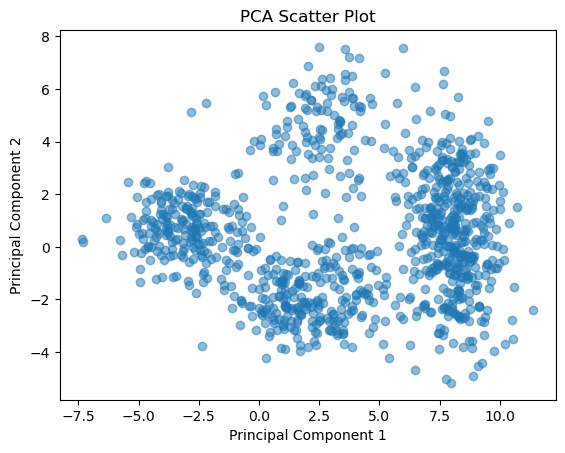

In [11]:
# Plotting
plt.scatter(projected_data[:, 0], projected_data[:, 1], alpha=0.5)
plt.title("PCA Scatter Plot")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

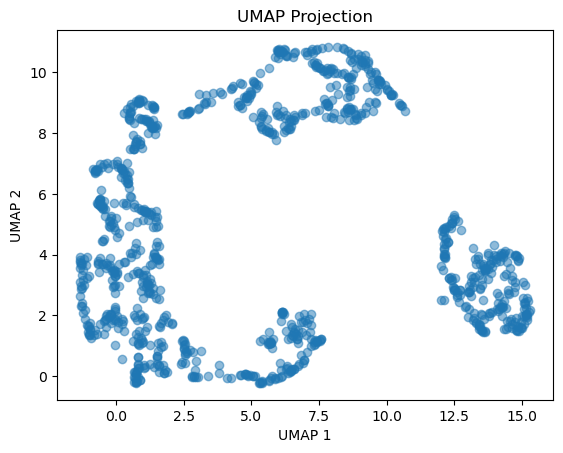

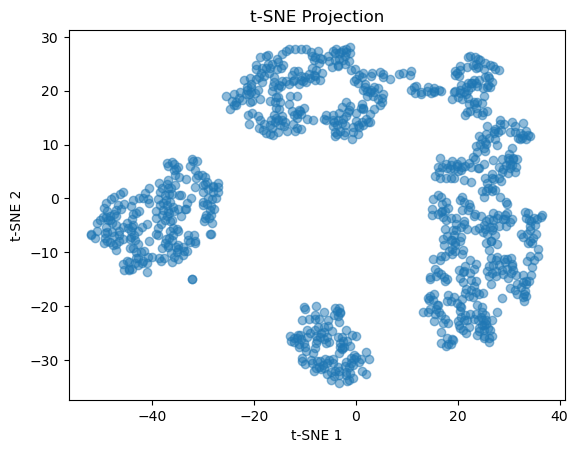

In [12]:
import umap
from sklearn.manifold import TSNE

# UMAP
umap_model = umap.UMAP()
umap_projection = umap_model.fit_transform(data)

plt.scatter(umap_projection[:, 0], umap_projection[:, 1], alpha=0.5)
plt.title("UMAP Projection")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.show()

# t-SNE
tsne_model = TSNE(n_components=2)
tsne_projection = tsne_model.fit_transform(data)

plt.scatter(tsne_projection[:, 0], tsne_projection[:, 1], alpha=0.5)
plt.title("t-SNE Projection")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.show()

In [14]:
from scipy.stats import poisson

def poisson_em(data, max_iter=100, tol=1e-4):
    # Initialize parameters
    λ1, λ2 = np.random.uniform(0, 10, 2)
    π = 0.5

    for i in range(max_iter):
        # E-step
        resp1 = π * poisson.pmf(data, λ1)
        resp2 = (1 - π) * poisson.pmf(data, λ2)
        total_resp = resp1 + resp2
        gamma = resp1 / total_resp

        # M-step
        λ1_new = np.sum(gamma * data) / np.sum(gamma)
        λ2_new = np.sum((1 - gamma) * data) / np.sum(1 - gamma)
        π_new = np.mean(gamma)

        # Check convergence
        if np.abs(λ1_new - λ1) < tol and np.abs(λ2_new - λ2) < tol and np.abs(π_new - π) < tol:
            break

        λ1, λ2, π = λ1_new, λ2_new, π_new

    return λ1, λ2, π

# Load data
data = np.loadtxt("D:\\4-2\\CSE 472 - ML\\Assingment 4\\em_data.txt")

# Run EM algorithm
mean_with_advice, mean_without_advice, proportion_with_advice = poisson_em(data)

# Print results
print(f"Mean number of children in families with family planning: {mean_with_advice}")
print(f"Mean number of children in families without family planning: {mean_without_advice}")
print(f"Proportion of families with family planning: {proportion_with_advice}")
print(f"Proportion of families without family planning: {1 - proportion_with_advice}")

Mean number of children in families with family planning: 1.7898782090583936
Mean number of children in families without family planning: 4.917061898443702
Proportion of families with family planning: 0.3581695255848132
Proportion of families without family planning: 0.6418304744151868
